# Telco Customer Churn: KPI Analysis and Classification Models

**Assessment:** ML and AI Algorithms — Assessment 1 Portfolio  
**Purpose:** Analyse an early-tenure churn exposure KPI and compare two supervised classifiers for the recorded churn label.

## Business question
How can a telecommunications provider use customer and service information to understand early-tenure churn exposure and support more targeted retention decisions?

## KPI definition
**Early-tenure revenue-weighted churn exposure (%)** is the sum of `MonthlyCharges` for recorded churners whose `tenure` is at most six months, divided by the sum of `MonthlyCharges` for all customers whose `tenure` is at most six months, multiplied by 100.

\[
\text{Early-tenure churn exposure (\%)} =
\frac{\sum \text{MonthlyCharges for churned customers with tenure} \leq 6}
{\sum \text{MonthlyCharges for all customers with tenure} \leq 6}
\times 100
\]

The KPI is derived from `tenure`, `Churn`, and `MonthlyCharges`. It is a descriptive snapshot indicator: it is **not** verified lifetime revenue lost and is **not** a future six-month churn probability.

## Relationship between KPI and ML target
The KPI is a cohort-level aggregate, while the models classify the individual-level recorded `Churn` label (`No = 0`, `Yes = 1`). The models therefore support investigation of customer-level churn patterns relevant to retention; they do not directly predict the KPI value.

## Assessment alignment
This notebook documents the dataset profile, cleaning, missing-data handling, feature suitability and leakage checks, requested Spearman correlation screen, train/test split, preprocessing, two algorithms, hyperparameter tuning, held-out evaluation, model interpretation, recommendations and limitations.

**Reproducibility:** Place `telco_churn_with_all_feedback.csv` in a `Datasets` folder beside this notebook (or update `DATA_PATH` in Section 2). The dataset itself is not embedded in this notebook.


In [1]:
# 1. Imports and reproducibility
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 3.0.3 | NumPy: 2.4.4


## 2. Load the dataset

In [2]:
# Locate the supplied dataset without relying on a personal absolute path.
DATA_FILENAME = "telco_churn_with_all_feedback.csv"
candidate_paths = [
    Path("Datasets") / DATA_FILENAME,
    Path(DATA_FILENAME),
    Path("../Datasets") / DATA_FILENAME,
    Path("../") / DATA_FILENAME,
    Path("../../Datasets") / DATA_FILENAME,
]
DATA_PATH = next((candidate for candidate in candidate_paths if candidate.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Put it in a 'Datasets' folder beside this notebook "
        "or update DATA_PATH in this cell to match your local project structure."
    )

telco_raw = pd.read_csv(DATA_PATH)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Dataset shape: {telco_raw.shape[0]:,} rows × {telco_raw.shape[1]} columns")
display(telco_raw.head())

# Validate the dataset schema before proceeding.
expected_columns = {
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents", "tenure",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
    "PromptInput", "CustomerFeedback"
}
missing_columns = expected_columns - set(telco_raw.columns)
unexpected_columns = set(telco_raw.columns) - expected_columns
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_columns)}")
if unexpected_columns:
    print("Note: additional columns found and not documented in the expected 23-column profile:",
          sorted(unexpected_columns))
if telco_raw.shape[1] < 23:
    raise ValueError("Expected the supplied 23-column dataset. Please check the selected CSV file.")


Loaded: /Users/ifadha/Documents/MSc in Datascience and AI/Y2/Sem1/ML and AI /Assessment 1 Portfolio/Datasets/telco_churn_with_all_feedback.csv
Dataset shape: 7,043 rows × 23 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,PromptInput,CustomerFeedback
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 1 months\nContrac...,"I have been using the DSL internet service from this provider for the past month and so far, I a..."
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 34 months\nContra...,I have been a customer with this company for over two and a half years now and I have been very ...
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,Write a realistic customer feedback based on this profile:\nChurn: Yes\nTenure: 2 months\nContra...,I recently signed up for DSL internet service with this provider two months ago on a month-to-mo...
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Write a realistic customer feedback based on this profile:\nChurn: No\nTenure: 45 months\nContra...,I have been a loyal customer with this company for 45 months now and I am very satisfied with th...
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,Write a realistic customer feedback based on this profile:\nChurn: Yes\nTenure: 2 months\nContra...,I recently switched to this fiber optic internet service provider two months ago on a month-to-m...


## 3. Dataset profile and data dictionary

This dictionary covers all 23 original attributes. The conceptual data types describe how the fields should be interpreted; actual pandas types are displayed separately. `TotalCharges` is stored as text in the supplied file and is converted to numeric during cleaning.

In [3]:
data_dictionary = pd.DataFrame([
("customerID", "Unique customer identifier; not a generalisable predictor.", "Identifier/categorical"),
("gender", "Recorded customer gender category.", "Categorical"),
("SeniorCitizen", "Senior-citizen indicator coded 0/1.", "Binary integer"),
("Partner", "Whether the customer has a partner.", "Binary categorical"),
("Dependents", "Whether the customer has dependents.", "Binary categorical"),
("tenure", "Number of months the customer has remained with the provider.", "Numerical integer"),
("PhoneService", "Whether phone service is subscribed to.", "Binary categorical"),
("MultipleLines", "Phone line subscription status/category.", "Categorical"),
("InternetService", "Internet service type.", "Categorical"),
("OnlineSecurity", "Online security subscription status/category.", "Categorical"),
("OnlineBackup", "Online backup subscription status/category.", "Categorical"),
("DeviceProtection", "Device protection subscription status/category.", "Categorical"),
("TechSupport", "Technical support subscription status/category.", "Categorical"),
("StreamingTV", "Streaming TV subscription status/category.", "Categorical"),
("StreamingMovies", "Streaming movies subscription status/category.", "Categorical"),
("Contract", "Contract duration/type.", "Categorical"),
("PaperlessBilling", "Whether paperless billing is used.", "Binary categorical"),
("PaymentMethod", "Recorded payment method.", "Categorical"),
("MonthlyCharges", "Monthly service charges recorded for the customer.", "Numerical decimal"),
("TotalCharges", "Total charges recorded for the customer; converted to numeric.", "Numerical decimal after cleaning"),
("Churn", "Recorded churn status (Yes/No); target label.", "Binary categorical target"),
("PromptInput", "Text prompt built from profile details and containing target information.", "Text; excluded from predictors"),
("CustomerFeedback", "Feedback text that may encode cancellation/switching outcome.", "Text; excluded from predictors")
], columns=["Attribute", "Description", "Conceptual data type"])
display(data_dictionary)
print("Actual pandas dtypes:")
display(telco_raw.dtypes.rename("Pandas dtype").to_frame())
print("Duplicate rows:", int(telco_raw.duplicated().sum()))
print("Missing values before cleaning:")
display(telco_raw.isna().sum().rename("Missing count").to_frame())

# Check that the dictionary covers the original expected schema.
dictionary_columns = set(data_dictionary["Attribute"])
print("Dictionary attributes:", len(dictionary_columns))
print("Expected source attributes:", len(expected_columns))
if dictionary_columns != expected_columns:
    print("Dictionary/schema mismatch — review before continuing.")
    print("Missing dictionary entries:", sorted(expected_columns - dictionary_columns))
    print("Extra dictionary entries:", sorted(dictionary_columns - expected_columns))
else:
    print("Data dictionary covers all 23 expected original attributes.")


,Attribute,Description,Conceptual data type
0,customerID,Unique customer identifier; not a generalisable predictor.,Identifier/categorical
1,gender,Recorded customer gender category.,Categorical
2,SeniorCitizen,Senior-citizen indicator coded 0/1.,Binary integer
3,Partner,Whether the customer has a partner.,Binary categorical
4,Dependents,Whether the customer has dependents.,Binary categorical
5,tenure,Number of months the customer has remained with the provider.,Numerical integer
6,PhoneService,Whether phone service is subscribed to.,Binary categorical
7,MultipleLines,Phone line subscription status/category.,Categorical
8,InternetService,Internet service type.,Categorical
9,OnlineSecurity,Online security subscription status/category.,Categorical


Actual pandas dtypes:


,Pandas dtype
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Duplicate rows: 0
Missing values before cleaning:


,Missing count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Dictionary attributes: 23
Expected source attributes: 23
Data dictionary covers all 23 expected original attributes.


## 4. Data cleaning and validation

Whitespace-only values are converted to missing values before `TotalCharges` is converted to numeric. In this dataset, 11 blank `TotalCharges` records correspond to zero-tenure customers; retain them because their other fields and churn labels remain usable. `TotalCharges` is excluded from the initial predictor set. Imputation for selected model inputs occurs inside training pipelines, avoiding preprocessing fitted on the held-out test set.

In [4]:
telco = telco_raw.copy()
text_columns = telco.select_dtypes(include=["object", "str"]).columns
for col in text_columns:
    telco[col] = telco[col].map(lambda v: np.nan if isinstance(v, str) and v.strip() == "" else v)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
if not set(telco["Churn"].dropna().unique()).issubset({"Yes", "No"}):
    raise ValueError("Unexpected values in Churn; inspect labels before modelling.")
print("Shape after cleaning:", telco.shape)
print("Duplicate rows:", int(telco.duplicated().sum()))
print("Missing values after cleaning:")
display(telco.isna().sum().rename("Missing count").to_frame())
print("Missing TotalCharges records (inspect tenure and label):")
display(telco.loc[telco["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "Churn"]])
print("Target distribution:")
display(telco["Churn"].value_counts().rename_axis("Churn").to_frame("Count").assign(Percentage=lambda d: (100*d.Count/len(telco)).round(2)))

Shape after cleaning: (7043, 23)
Duplicate rows: 0
Missing values after cleaning:


,Missing count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Missing TotalCharges records (inspect tenure and label):


,tenure,MonthlyCharges,Churn
488,0,52.55,No
1218,0,19.70,No
2670,0,73.35,No
2754,0,61.90,No
3296,0,20.25,No
3479,0,80.85,No
3625,0,25.75,No
3883,0,56.05,No
5874,0,19.85,No
6369,0,25.35,No


Target distribution:


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


## 5. KPI calculation and exploratory analysis

The KPI helps a retention manager quantify how much of the cohort's recorded monthly charges is associated with customers who have churned early in their relationship. It can support prioritisation of onboarding and retention investigations. It should not be interpreted as a causal effect or a confirmed financial loss.


Early-tenure cohort: 1,481 customers
Recorded churners in cohort: 784
Sum of monthly charges for cohort: 81,067.95
Sum of monthly charges for recorded churners: 49,896.10
Early-tenure revenue-weighted churn exposure: 61.55%
This is a descriptive snapshot KPI, not verified permanent revenue loss or a future churn probability.
Overall recorded churn rate: 26.54%


,Customers,Churners,ChurnRate_pct
TenureBand,,,
0–6 months,1481,784,52.94
7–12 months,705,253,35.89
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49–72 months,2239,213,9.51


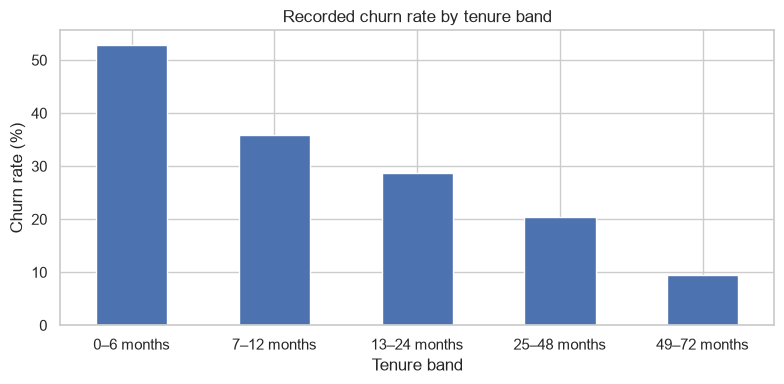

Churn rate by Contract:


,Customers,Churners,ChurnRate_pct
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


Churn rate by InternetService:


,Customers,Churners,ChurnRate_pct
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40


Churn rate by PaymentMethod:


,Customers,Churners,ChurnRate_pct
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


In [5]:
EARLY_TENURE_MAX_MONTHS = 6
early = telco.loc[telco["tenure"].le(EARLY_TENURE_MAX_MONTHS)].copy()
early_total_charges = early["MonthlyCharges"].sum()
early_churned_charges = early.loc[early["Churn"].eq("Yes"), "MonthlyCharges"].sum()
early_churn_count = int(early["Churn"].eq("Yes").sum())
kpi_value = 100 * early_churned_charges / early_total_charges if early_total_charges else np.nan
print(f"Early-tenure cohort: {len(early):,} customers")
print(f"Recorded churners in cohort: {early_churn_count:,}")
print(f"Sum of monthly charges for cohort: {early_total_charges:,.2f}")
print(f"Sum of monthly charges for recorded churners: {early_churned_charges:,.2f}")
print(f"Early-tenure revenue-weighted churn exposure: {kpi_value:.2f}%")
print("This is a descriptive snapshot KPI, not verified permanent revenue loss or a future churn probability.")
print(f"Overall recorded churn rate: {100*telco['Churn'].eq('Yes').mean():.2f}%")

bins = [-1, 6, 12, 24, 48, 72]
labels = ["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
telco["TenureBand"] = pd.cut(telco["tenure"], bins=bins, labels=labels)
tenure_summary = telco.groupby("TenureBand", observed=False).agg(
    Customers=("Churn", "size"), Churners=("Churn", lambda s: s.eq("Yes").sum()))
tenure_summary["ChurnRate_pct"] = (100*tenure_summary.Churners/tenure_summary.Customers).round(2)
display(tenure_summary)
ax = tenure_summary["ChurnRate_pct"].plot(kind="bar", figsize=(8,4), rot=0)
ax.set(title="Recorded churn rate by tenure band", xlabel="Tenure band", ylabel="Churn rate (%)")
plt.tight_layout(); plt.show()
for col in ["Contract", "InternetService", "PaymentMethod"]:
    summary = telco.groupby(col, dropna=False).agg(Customers=("Churn", "size"), Churners=("Churn", lambda s: s.eq("Yes").sum()))
    summary["ChurnRate_pct"] = (100*summary.Churners/summary.Customers).round(2)
    print(f"Churn rate by {col}:"); display(summary.sort_values("ChurnRate_pct", ascending=False))

## 6. Feature suitability and leakage prevention

`Churn` is encoded as `ChurnFlag` (1 = Yes, 0 = No). `customerID` is excluded because it is an identifier. `PromptInput` is excluded because it explicitly contains the recorded churn label; `CustomerFeedback` is excluded because its generated text may mention cancellation/switching and encode outcome information. Including these text fields risks target leakage. `TotalCharges` is omitted from the initial model because it contains 11 missing values and is strongly related to tenure. This is a deliberate initial feature-set choice, not a claim that it could never be useful.

In [6]:
telco["ChurnFlag"] = telco["Churn"].map({"No": 0, "Yes": 1}).astype(int)
feature_columns = ["gender", "SeniorCitizen", "Partner", "Dependents", "tenure", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod", "MonthlyCharges"]
X = telco[feature_columns].copy()
y = telco["ChurnFlag"].copy()
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
print("Predictor count:", len(feature_columns), "| X:", X.shape, "| y:", y.shape)
print("Target mapping: No=0, Yes=1")
print("Excluded: customerID, TotalCharges, Churn, PromptInput, CustomerFeedback, TenureBand, ChurnFlag")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Predictor count: 18 | X: (7043, 18) | y: (7043,)
Target mapping: No=0, Yes=1
Excluded: customerID, TotalCharges, Churn, PromptInput, CustomerFeedback, TenureBand, ChurnFlag
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 7. Spearman correlation / independence and leakage screening

The assessment brief asks for a Pearson or Spearman test between inputs and the target KPI. The chosen KPI is an **aggregate across an early-tenure cohort**, so it is not a row-level target that can be meaningfully correlated separately with each customer's features. For the requested univariate screen, this notebook tests selected input features against the individual-level binary `ChurnFlag`, the label used by the classification models. This distinction is stated explicitly to avoid claiming that the models directly predict the aggregate KPI.

Categorical predictors are one-hot encoded for this screen. Spearman's rho describes monotonic association; the p-value tests against zero correlation. This is **not proof of independence**, and p-values are interpreted cautiously because many features are tested. The results are not used for feature selection, and the screen is not a substitute for checking how each field was constructed. `PromptInput` and `CustomerFeedback` remain excluded because they may encode the outcome.


In [7]:
X_corr = pd.get_dummies(X, drop_first=False, dtype=int)
correlation_results = []
for feature in X_corr.columns:
    # Constant columns can produce undefined correlation; retain them transparently.
    if X_corr[feature].nunique(dropna=True) < 2:
        rho, p_value = np.nan, np.nan
    else:
        rho, p_value = spearmanr(X_corr[feature], y)
    correlation_results.append({
        "Feature": feature,
        "Spearman_rho": rho,
        "p_value": p_value,
        "Absolute_correlation": abs(rho) if pd.notna(rho) else np.nan
    })

correlation_df = (
    pd.DataFrame(correlation_results)
    .sort_values("Absolute_correlation", ascending=False, na_position="last")
    .reset_index(drop=True)
)
display(correlation_df.round(4))
print("Positive rho indicates association with Churn=Yes under 1/0 target coding; negative rho indicates association with Churn=No.")
print("A small p-value is not evidence of causation or business importance. Correlation does not establish independence.")
print("The screen is descriptive and is not used to select features.")


,Feature,Spearman_rho,p_value,Absolute_correlation
0,Contract_Month-to-month,0.4051,0.0000,0.4051
1,tenure,-0.3671,0.0000,0.3671
2,OnlineSecurity_No,0.3426,0.0000,0.3426
3,TechSupport_No,0.3373,0.0000,0.3373
4,InternetService_Fiber optic,0.3080,0.0000,0.3080
5,Contract_Two year,-0.3023,0.0000,0.3023
6,PaymentMethod_Electronic check,0.3019,0.0000,0.3019
7,OnlineBackup_No,0.2680,0.0000,0.2680
8,DeviceProtection_No,0.2525,0.0000,0.2525
9,InternetService_No,-0.2279,0.0000,0.2279


Positive rho indicates association with Churn=Yes under 1/0 target coding; negative rho indicates association with Churn=No.
A small p-value is not evidence of causation or business importance. Correlation does not establish independence.
The screen is descriptive and is not used to select features.


## 8. Train-test split and preprocessing

A stratified 80/20 split preserves class proportions. The test set is reserved for final evaluation; tuning uses only training data. Imputation and encoding are inside pipelines so each training fold fits its own transformations. Logistic Regression uses standard scaling for numeric inputs; Random Forest does not require scaling for tree splits.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Training churn rate:", round(100*y_train.mean(),2), "% | Test churn rate:", round(100*y_test.mean(),2), "%")
numeric_lr = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
numeric_rf = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor_lr = ColumnTransformer([("numeric", numeric_lr, numeric_features), ("categorical", categorical_transformer, categorical_features)])
preprocessor_rf = ColumnTransformer([("numeric", numeric_rf, numeric_features), ("categorical", categorical_transformer, categorical_features)])
print("Preprocessing: median numeric imputation; most-frequent categorical imputation; one-hot encoding; scaling for Logistic Regression.")

X_train: (5634, 18) X_test: (1409, 18)
Training churn rate: 26.54 % | Test churn rate: 26.54 %
Preprocessing: median numeric imputation; most-frequent categorical imputation; one-hot encoding; scaling for Logistic Regression.


## 9. Baseline model training and evaluation

**Logistic Regression** provides a relatively interpretable linear baseline. **Random Forest** is an ensemble of decision trees that can represent nonlinear relationships and interactions. Both are appropriate supervised binary classifiers for the recorded churn label.

In [9]:
baseline_models = {
 "Logistic Regression": Pipeline([("preprocessor", preprocessor_lr), ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
 "Random Forest": Pipeline([("preprocessor", preprocessor_rf), ("classifier", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
}
def evaluate_classifier(name, model, X_eval, y_eval):
    pred = model.predict(X_eval); score = model.predict_proba(X_eval)[:,1]
    return {"Model": name, "Accuracy": accuracy_score(y_eval,pred), "Precision": precision_score(y_eval,pred,zero_division=0),
            "Recall": recall_score(y_eval,pred,zero_division=0), "F1": f1_score(y_eval,pred,zero_division=0), "ROC_AUC": roc_auc_score(y_eval,score)}
baseline_results=[]
for name, model in baseline_models.items():
    model.fit(X_train,y_train); baseline_results.append(evaluate_classifier(name,model,X_test,y_test))
baseline_results_df = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_results_df.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.7991,0.6426,0.5481,0.5916,0.8463
Random Forest,0.7807,0.6080,0.4893,0.5422,0.8191


## 10. Hyperparameter tuning

Both models are tuned with five-fold stratified cross-validation on the training data only. F1 is the refit objective because churn is the minority class and the metric balances precision and recall. The held-out test set is not used to select parameters.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"precision":"precision", "recall":"recall", "f1":"f1", "roc_auc":"roc_auc"}
param_grids = {
 "Logistic Regression": {"classifier__C":[0.1,1.0,10.0], "classifier__class_weight":[None,"balanced"]},
 "Random Forest": {"classifier__n_estimators":[200,400], "classifier__max_depth":[None,10,20],
                    "classifier__min_samples_leaf":[1,3], "classifier__class_weight":[None,"balanced"]}
}
tuned_models={}; tuning_summaries=[]
for name, pipeline in baseline_models.items():
    search=GridSearchCV(pipeline,param_grids[name],scoring=scoring,refit="f1",cv=cv,n_jobs=-1,return_train_score=False)
    search.fit(X_train,y_train); tuned_models[name]=search.best_estimator_; i=search.best_index_
    tuning_summaries.append({"Model":name,"Best parameters":search.best_params_,"Best CV F1":search.best_score_,
        "CV F1 std":search.cv_results_["std_test_f1"][i],"CV precision":search.cv_results_["mean_test_precision"][i],
        "CV recall":search.cv_results_["mean_test_recall"][i],"CV ROC-AUC":search.cv_results_["mean_test_roc_auc"][i]})
tuning_results_df=pd.DataFrame(tuning_summaries).set_index("Model")
display(tuning_results_df.round(4))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warn

,Best parameters,Best CV F1,CV F1 std,CV precision,CV recall,CV ROC-AUC
Model,,,,,,
Logistic Regression,"{'classifier__C': 1.0, 'classifier__class_weight': 'balanced'}",0.6274,0.0144,0.5206,0.7900,0.8413
Random Forest,"{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_l...",0.6361,0.0171,0.5610,0.7351,0.8390


## 11. Final held-out test-set evaluation

All final metrics below are calculated on the held-out test set after tuning on training data only.

- **Accuracy:** proportion of all test records classified correctly.
- **Precision:** proportion of predicted churners who are recorded churners; relevant to unnecessary outreach.
- **Recall:** proportion of recorded churners identified; relevant to missed churners.
- **F1-score:** harmonic mean of precision and recall; used as the tuning objective.
- **ROC-AUC:** ability to rank churners above non-churners across classification thresholds.

No single metric alone determines the best model. The default classification threshold is used here; threshold optimisation against real outreach costs is outside this assessment.


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.7466,0.5145,0.8075,0.6285,0.8461
Random Forest,0.7665,0.5440,0.7433,0.6282,0.8488



Logistic Regression — classification report
              precision    recall  f1-score   support

    No churn       0.91      0.72      0.81      1035
       Churn       0.51      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



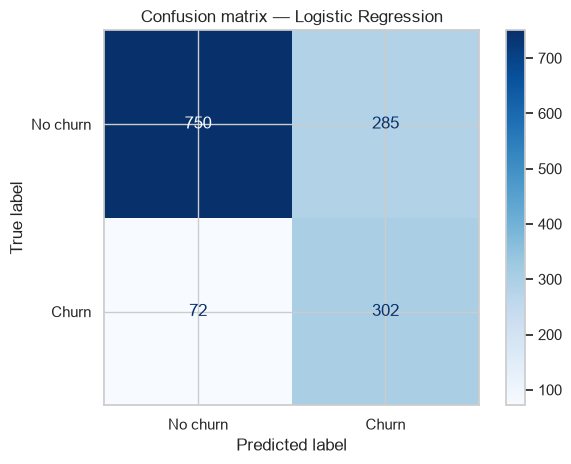


Random Forest — classification report
              precision    recall  f1-score   support

    No churn       0.89      0.77      0.83      1035
       Churn       0.54      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



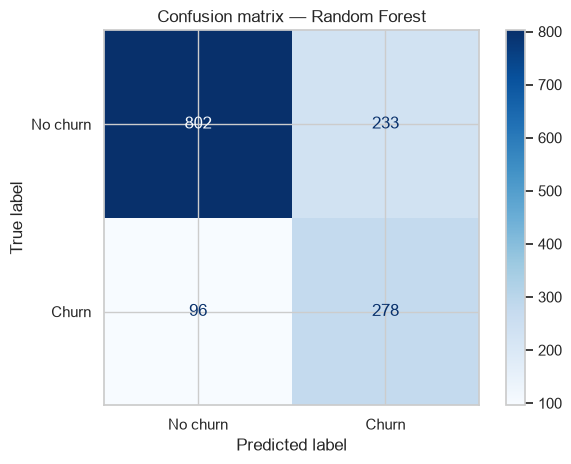

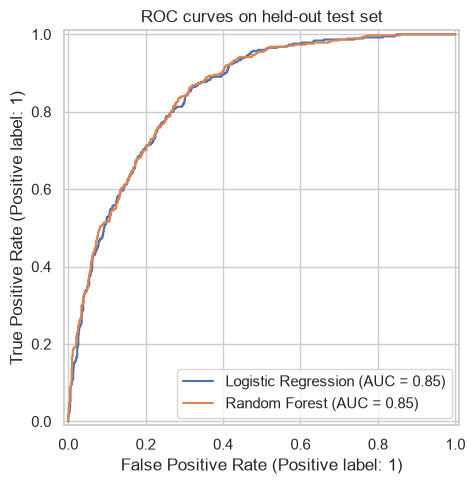

In [11]:
tuned_results=[]
for name, model in tuned_models.items(): tuned_results.append(evaluate_classifier(name,model,X_test,y_test))
final_results_df=pd.DataFrame(tuned_results).set_index("Model")
display(final_results_df.round(4))
for name, model in tuned_models.items():
    print(f"\n{name} — classification report")
    print(classification_report(y_test,model.predict(X_test),target_names=["No churn","Churn"],zero_division=0))
    ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,display_labels=["No churn","Churn"],cmap="Blues",values_format="d")
    plt.title(f"Confusion matrix — {name}"); plt.tight_layout(); plt.show()
fig, ax=plt.subplots(figsize=(7,5))
for name, model in tuned_models.items(): RocCurveDisplay.from_estimator(model,X_test,y_test,name=name,ax=ax)
ax.set_title("ROC curves on held-out test set"); plt.tight_layout(); plt.show()

## 12. Permutation importance

Permutation importance estimates how much the selected model's ROC-AUC changes when each input feature is shuffled. It is a descriptive model-interpretation method, not a causal effect. Correlated features can share predictive information, so an individual feature can appear less important when similar information is present elsewhere.

,Feature,Mean ROC-AUC decrease,Standard deviation
0,tenure,0.0877,0.0074
1,InternetService,0.0392,0.0053
2,Contract,0.0332,0.0044
3,MonthlyCharges,0.0190,0.0026
4,StreamingMovies,0.0043,0.0019
5,PaymentMethod,0.0037,0.0008
6,StreamingTV,0.0037,0.0015
7,OnlineSecurity,0.0029,0.0012
8,TechSupport,0.0027,0.0010
9,MultipleLines,0.0027,0.0018


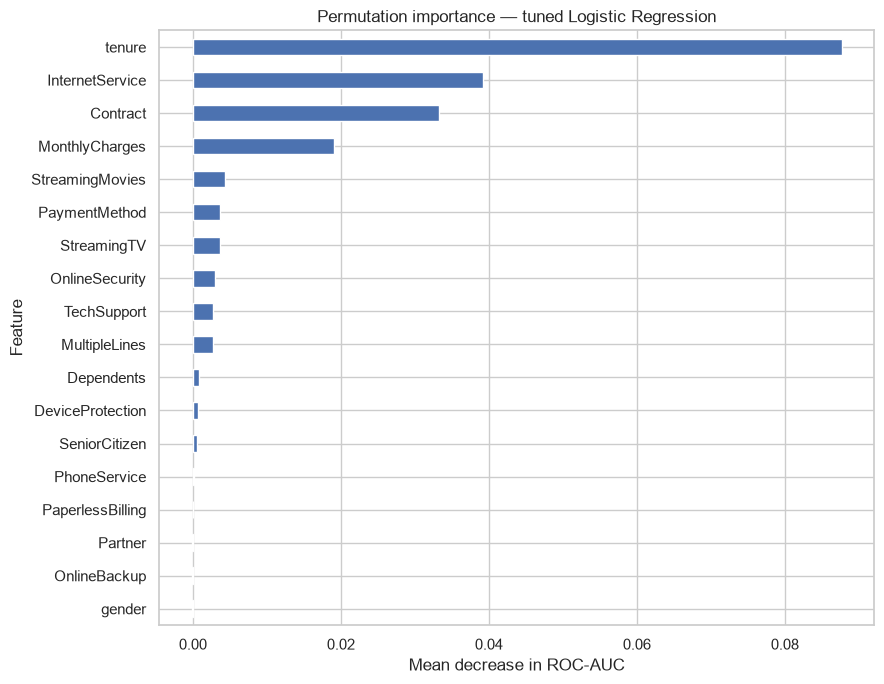

In [12]:
importance_model=tuned_models["Logistic Regression"]
perm=permutation_importance(importance_model,X_test,y_test,scoring="roc_auc",n_repeats=10,random_state=RANDOM_STATE,n_jobs=-1)
importance_df=pd.DataFrame({"Feature":X_test.columns,"Mean ROC-AUC decrease":perm.importances_mean,"Standard deviation":perm.importances_std}).sort_values("Mean ROC-AUC decrease",ascending=False).reset_index(drop=True)
display(importance_df.round(4))
plot_df=importance_df.sort_values("Mean ROC-AUC decrease",ascending=True)
ax=plot_df.plot(x="Feature",y="Mean ROC-AUC decrease",kind="barh",legend=False,figsize=(9,7),xerr=plot_df["Standard deviation"])
ax.set(title="Permutation importance — tuned Logistic Regression",xlabel="Mean decrease in ROC-AUC",ylabel="Feature")
plt.tight_layout(); plt.show()

## 13. Baseline versus tuned comparison

Accuracy  Precision  Recall      F1  ROC_AUC
Stage    Model                                                            
Baseline Logistic Regression    0.7991     0.6426  0.5481  0.5916   0.8463
         Random Forest          0.7807     0.6080  0.4893  0.5422   0.8191
Tuned    Logistic Regression    0.7466     0.5145  0.8075  0.6285   0.8461
         Random Forest          0.7665     0.5440  0.7433  0.6282   0.8488

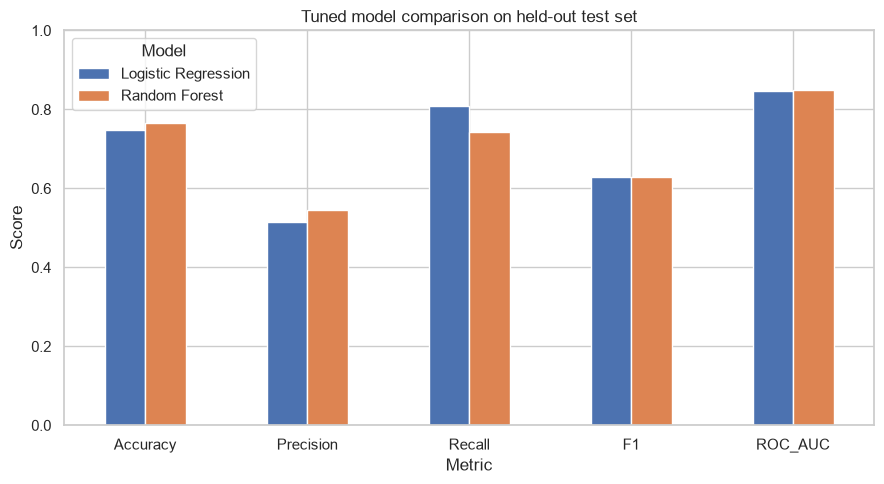

In [13]:
comparison_df=pd.concat({"Baseline":baseline_results_df,"Tuned":final_results_df},names=["Stage","Model"])
display(comparison_df.round(4))
report_metrics=["Accuracy","Precision","Recall","F1","ROC_AUC"]
ax=final_results_df[report_metrics].T.plot(kind="bar",figsize=(9,5),rot=0)
ax.set(title="Tuned model comparison on held-out test set",ylabel="Score",xlabel="Metric",ylim=(0,1))
plt.tight_layout(); plt.show()

## 14. Business interpretation, recommendations and limitations

Use the actual values produced above in the report. Do not copy example metrics from an earlier run if they differ after fresh execution.

### Interpretation and recommendations

- Compare tuned models using recall, precision, F1 and ROC-AUC, not accuracy alone.
- Higher recall means more recorded churners are identified, but may create more false-positive alerts. Choose based on outreach cost and capacity.
- Translate important predictors into testable hypotheses: improve early onboarding, investigate service experience, clarify contract value, or review price/value perception where supported by results.
- Prioritise investigating early-tenure customers because the KPI quantifies churn exposure in this cohort.
- Test interventions through a controlled pilot. Treat model alerts as decision support rather than automatic decisions, and review false positives and false negatives before deployment.

### Limitations

- The model classifies the recorded churn label from a snapshot; it does not validate a future prediction horizon.
- The KPI is monthly charges associated with recorded churners, not verified lifetime revenue lost.
- Correlation and permutation importance do not establish causality.
- The operating threshold and business costs have not been optimised for a real retention budget.
- Results depend on the quality and representativeness of the supplied dataset.

## 15. Final reproducibility checklist

- [ ] Dataset path works from a fresh kernel.
- [ ] All cells run in order without errors.
- [ ] The 23-column dictionary matches the supplied file.
- [ ] Actual Spearman output is interpreted cautiously; no causal claims are made.
- [ ] `PromptInput` and `CustomerFeedback` remain excluded from predictors.
- [ ] Final metrics, confusion matrices, ROC curves and permutation importance are checked.
- [ ] Report statements match the freshly executed notebook.
- [ ] Report follows the required table structure and stays within 900–1,100 words.

### How to write up the actual results

After running all cells, use `final_results_df`, the confusion matrices, `importance_df`, and `correlation_df` to describe the observed results. Do not copy old values if fresh execution produces different metrics.

When comparing models, explicitly discuss the trade-off: higher recall can identify more churners but may also increase false-positive outreach. Recommend a model only in relation to the business objective and outreach capacity. Treat high-importance features as predictive associations, not proven causes.
